In [1]:
import json

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde, norm

# plt.rc("font", family="Nimbus Roman")
plt.rc("font", family="Nimbus Roman No9 L")

SMALL_SIZE = 7
MEDIUM_SIZE = 7
BIGGER_SIZE = 7

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [2]:
sim_lst = ["m12b", "m12c", "m12f", "m12i", "m12m"]
sim_dir = "/Users/z5114326/Documents/simulations/"

all_data = sim_dir + "m12i" + "/" + "m12i" + "_res7100/snapshot_times.txt"
all_snaps = pd.read_table(all_data, comment="#", header=None, sep=r"\s+")
all_snaps.columns = [
    "index",
    "scale_factor",
    "redshift",
    "time_Gyr",
    "lookback_time_Gyr",
    "time_width_Myr",
]

tims = all_snaps["time_Gyr"].values
timez0 = tims[-1]

scmap = plt.get_cmap("tab10")
colors = [scmap(i) for i in np.linspace(0, 1, len(sim_lst))]
sim_colors = {sim: colors[i] for i, sim in enumerate(sim_lst)}

mw_gcs_fil = "../data/mw_gcs/mw_gc_ages.csv"
mw_gcs = pd.read_csv(mw_gcs_fil)

In [3]:
cnt_dict = {sim: {"tims": tims, "avg": None, "std": None} for sim in sim_lst}

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    arr = []
    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]

        tfor = src_dat["tfor"][()]
        tacc = src_dat["tacc"][()]
        tdis = src_dat["tdis"][()]
        tdis = np.where(tdis == -1, np.inf, tdis)

        cnts = np.zeros(len(tims))
        for i, tim in enumerate(tims):
            msk = (tfor <= tim) & (tacc <= tim) & (tim < tdis)
            cnts[i] = np.sum(msk)

        arr.append(cnts)

    cnt_dict[sim]["avg"] = np.mean(arr, axis=0)
    cnt_dict[sim]["std"] = np.std(arr, axis=0)

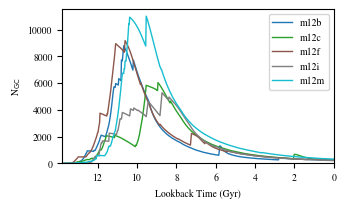

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(3.5, 2))

for sim in sim_lst:
    ax.plot(timez0 - cnt_dict[sim]["tims"], cnt_dict[sim]["avg"], c=sim_colors[sim], label=sim, lw=1)

ax.set_xlim(timez0, 0)
ax.set_ylim(0, 11500)

ax.set_xlabel("Lookback Time (Gyr)")
ax.set_ylabel(r"N$_{\rm GC}$")

ax.legend()

save_loc = "../data/figures/gc_plots/gc_counts.pdf"
plt.savefig(save_loc, bbox_inches="tight")

In [5]:
for sim in sim_lst:
    print(sim, np.round(cnt_dict[sim]["avg"][-1]), np.round(cnt_dict[sim]["std"][-1]))


m12b 235.0 51.0
m12c 240.0 61.0
m12f 252.0 42.0
m12i 212.0 52.0
m12m 326.0 72.0


In [6]:
for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    arr = []
    for it_id in ghost_data.keys():
        snp_dat = ghost_data[it_id]["snapshots"]["snap600"]
        arr.append(len(snp_dat["gcid"][()]))

    print(sim, np.round(np.mean(arr)), np.round(np.std(arr)))

m12b 234.0 51.0
m12c 237.0 61.0
m12f 250.0 42.0
m12i 211.0 52.0
m12m 324.0 71.0


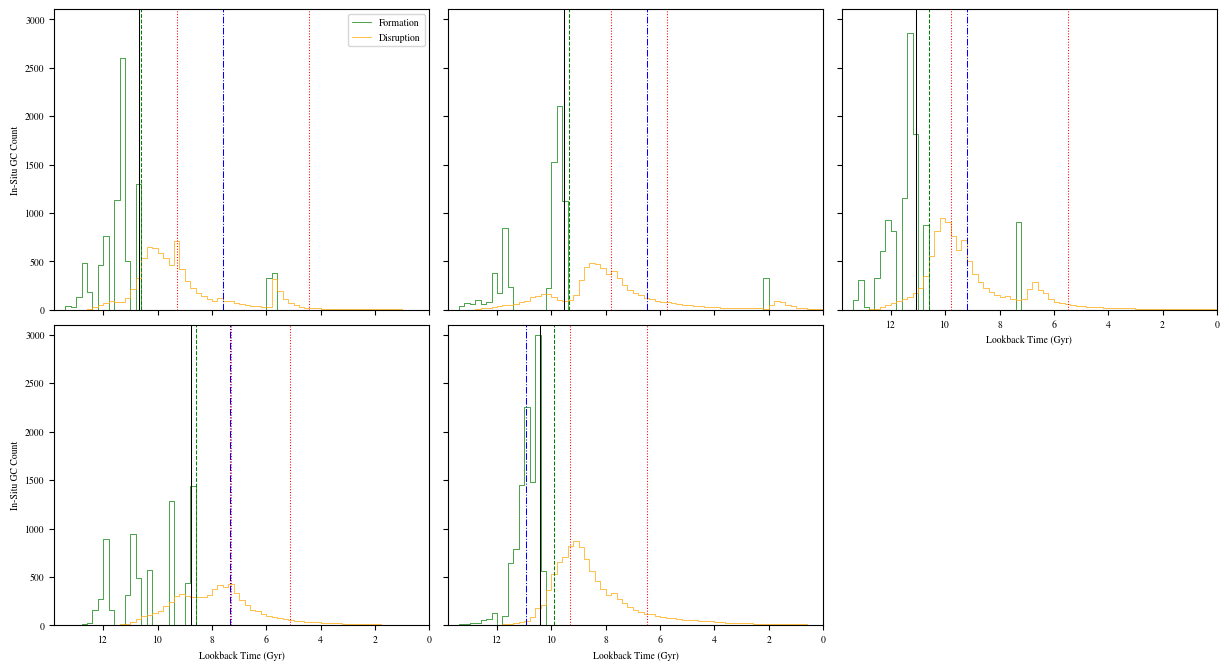

In [7]:
to_path = "../data/sim_data/turn_offs_lbt.json"
with open(to_path, "r", encoding="utf-8") as f:
    to_dict = json.load(f)

su_path = "../data/sim_data/spin_up_lbt.json"
with open(su_path, "r", encoding="utf-8") as f:
    su_dict = json.load(f)

bf_path = "../data/sim_data/boundary_formation_lbt.json"
with open(bf_path, "r", encoding="utf-8") as f:
    bf_dict = json.load(f)

bo_path = "../data/sim_data/boundary_onset_lbt.json"
with open(bo_path, "r", encoding="utf-8") as f:
    bo_dict = json.load(f)

em_path = "../data/sim_data/early_merger_lbt.json"
with open(em_path, "r", encoding="utf-8") as f:
    em_dict = json.load(f)

fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
plt.subplots_adjust(hspace=0.05, wspace=0.05)

for i, ax in enumerate(axs.flatten()):
    if i == 5:
        ax.axis("off")
        continue

    sim = sim_lst[i]
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    hist_dict = {"sum_for": None, "sum_dis": None, "n": 0}
    bins = np.arange(0, 14, 0.2)

    all_tfors = []
    all_tdiss = []
    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]
        insitu_msk = src_dat["grpid"][()] == 0
        tfors = timez0 - src_dat["tfor"][insitu_msk]
        tdiss = timez0 - src_dat["tdis"][insitu_msk]
        all_tfors.append(tfors)
        all_tdiss.append(tdiss)

        hssp_for, _ = np.histogram(tfors, bins=bins)
        hssp_dis, _ = np.histogram(tdiss, bins=bins)

        if hist_dict["sum_for"] is None:
            hist_dict["sum_for"] = hssp_for.astype(float)
            hist_dict["sum_dis"] = hssp_dis.astype(float)
        else:
            hist_dict["sum_for"] += hssp_for
            hist_dict["sum_dis"] += hssp_dis
        hist_dict["n"] += 1

    binsum_for = hist_dict["sum_for"] / hist_dict["n"]
    binsum_dis = hist_dict["sum_dis"] / hist_dict["n"]
    ax.step(bins[:-1], binsum_for, where="post", color="g", lw=0.5, label="Formation")
    ax.step(bins[:-1], binsum_dis, where="post", color="orange", lw=0.5, label="Disruption")

    if i == 0:
        ax.legend(loc="upper right")

    ax.set_xlim(timez0, 0)
    ax.set_ylim(0, 3100)

    if i in [2, 3, 4]:
        ax.set_xlabel("Lookback Time (Gyr)")

    if i in [0, 1]:
        ax.set_xticklabels([])

    if i in [0, 3]:
        ax.set_ylabel("In-Situ GC Count")

    if i in [1, 2, 4]:
        ax.set_yticklabels([])

    # ax.axvline(su_dict[sim])

    # ax.axvline(to_dict["cnt"][sim])

    ax.axvline(to_dict["cnt"][sim], c="g", ls="--", lw=0.75)
    ax.axvline(su_dict[sim], c="b", ls="-.", lw=0.75)
    ax.axvline(bf_dict["in_situ"][sim], c="r", ls=":", lw=0.75)
    ax.axvline(bo_dict["in_situ"][sim], c="r", ls=":", lw=0.75)
    ax.axvline(em_dict[sim], c="k", ls="-", lw=0.75)

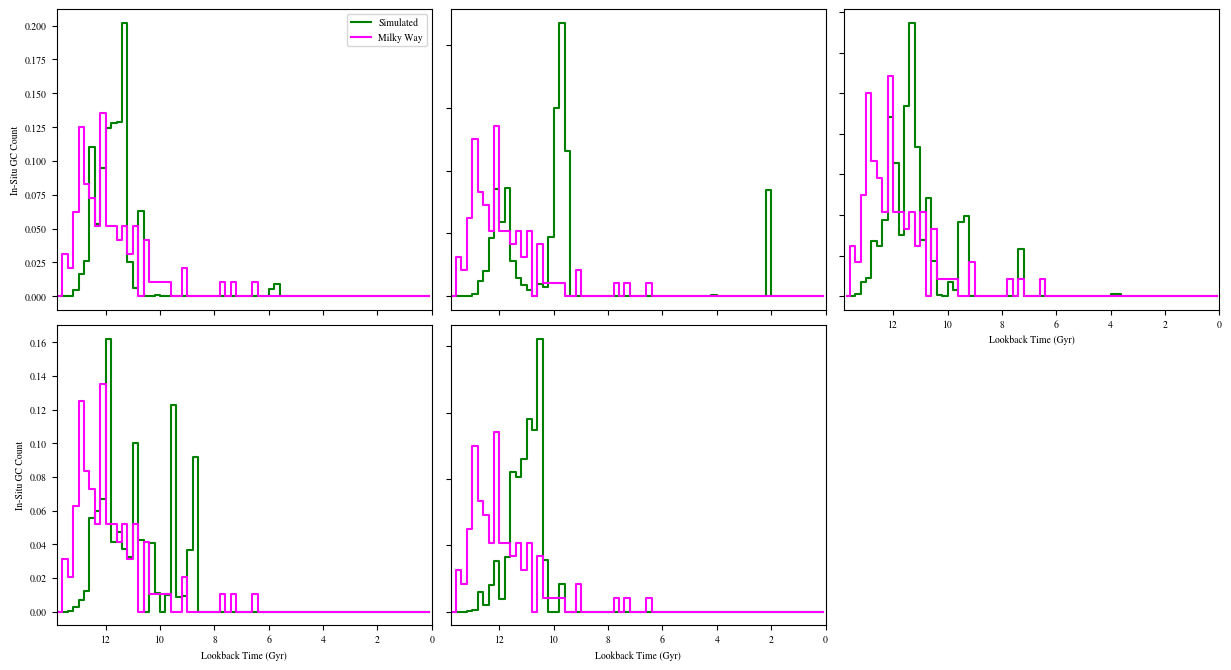

In [8]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
plt.subplots_adjust(hspace=0.05, wspace=0.05)

bins = np.arange(0, 14, 0.2)
bin_centres = 0.5 * (bins[1:] + bins[:-1])

for i, ax in enumerate(axs.flatten()):
    if i == 5:
        ax.axis("off")
        continue

    sim = sim_lst[i]
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    hist_dict = {"sum_for": None, "sum_dis": None, "n": 0}

    all_tfors = []
    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]
        smsk = src_dat["tdis"][()] == -1
        tfors = timez0 - src_dat["tfor"][smsk]

        all_tfors.append(tfors)

        hssp_for, _ = np.histogram(tfors, bins=bins)

        if hist_dict["sum_for"] is None:
            hist_dict["sum_for"] = hssp_for.astype(float)

        else:
            hist_dict["sum_for"] += hssp_for

        hist_dict["n"] += 1

    binsum_for = hist_dict["sum_for"] / hist_dict["n"]

    # Simulated population
    sim_counts = binsum_for
    sim_pdf = sim_counts / np.sum(sim_counts)

    # MW population
    mw_counts, _ = np.histogram(mw_gcs["Mean_tau"], bins=bins)
    mw_pdf = mw_counts / np.sum(mw_counts)

    ax.step(bin_centres, sim_pdf, where="mid", color="g", lw=1.5, label="Simulated")
    ax.step(bin_centres, mw_pdf, where="mid", color="magenta", lw=1.5, label="Milky Way")

    if i == 0:
        ax.legend(loc="upper right")

    ax.set_xlim(timez0, 0)
    # ax.set_ylim(0, 3100)

    if i in [2, 3, 4]:
        ax.set_xlabel("Lookback Time (Gyr)")

    if i in [0, 1]:
        ax.set_xticklabels([])

    if i in [0, 3]:
        ax.set_ylabel("In-Situ GC Count")

    if i in [1, 2, 4]:
        ax.set_yticklabels([])


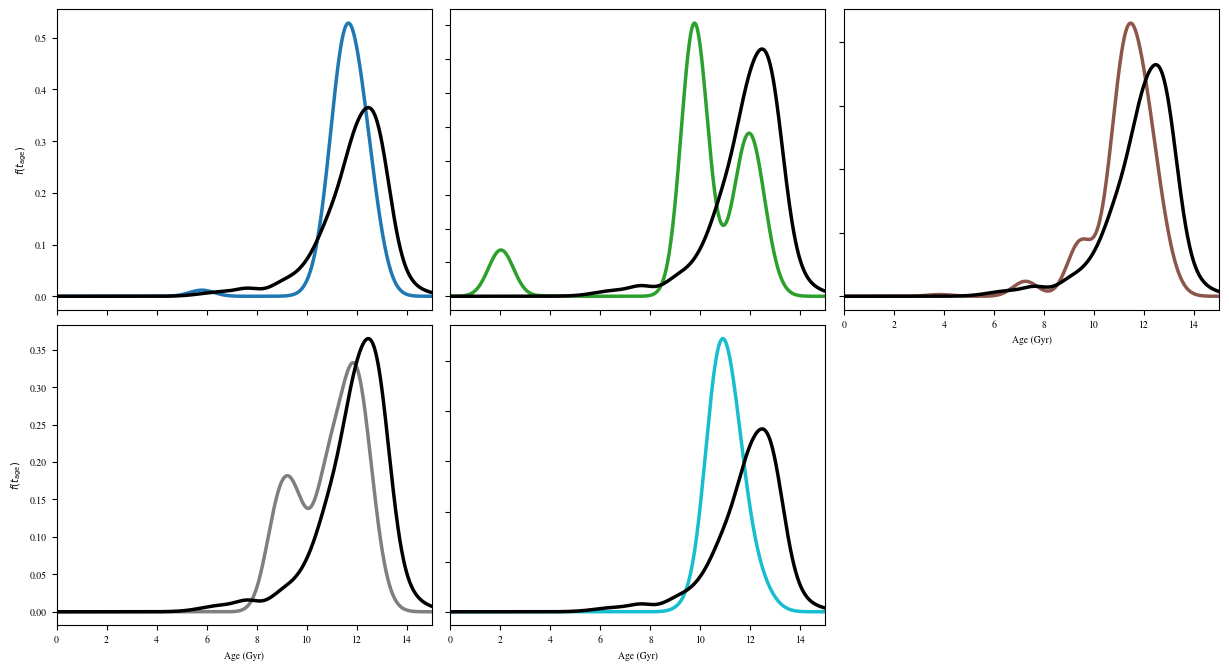

In [9]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
plt.subplots_adjust(hspace=0.05, wspace=0.05)

# Age grid for PDFs
tgrid = np.linspace(0, 15, 1000)

# Histogram bins
bins = np.arange(0, 15.2, 0.2)

# ----------------------------------------------------------
# MW PDF (computed once)
# ----------------------------------------------------------

pdf_mw = np.zeros_like(tgrid)

for age, err in zip(mw_gcs["Mean_tau"], mw_gcs["Mean_tau_err"]):
    pdf_mw += norm.pdf(tgrid, loc=age, scale=err)

pdf_mw /= len(mw_gcs)
pdf_mw /= np.trapz(pdf_mw, tgrid)

# ----------------------------------------------------------
# MW histogram (normalized)
# ----------------------------------------------------------

mw_counts, _ = np.histogram(mw_gcs["Mean_tau"], bins=bins, density=True)

bin_centres = 0.5 * (bins[:-1] + bins[1:])

# ----------------------------------------------------------
# Simulations
# ----------------------------------------------------------

for i, ax in enumerate(axs.flatten()):
    if i == 5:
        ax.axis("off")
        continue

    sim = sim_lst[i]

    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    pdf_sim = np.zeros_like(tgrid)
    hist_sim = np.zeros(len(bins) - 1)

    n_realizations = 0

    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]

        smsk = src_dat["tdis"][()] == -1
        tfors = timez0 - src_dat["tfor"][smsk]

        if len(tfors) == 0:
            continue

        # --------------------------
        # Histogram for realization
        # --------------------------

        h, _ = np.histogram(tfors, bins=bins, density=True)
        # h, _ = np.histogram(tfors, bins=bins, density=False)

        hist_sim += h

        # --------------------------
        # PDF for realization
        # --------------------------

        pdf_this = np.zeros_like(tgrid)

        for age in tfors:
            pdf_this += norm.pdf(tgrid, loc=age, scale=0.5)

        pdf_this /= len(tfors)
        pdf_this /= np.trapz(pdf_this, tgrid)

        pdf_sim += pdf_this

        n_realizations += 1

    hist_sim /= n_realizations
    pdf_sim /= n_realizations

    # ------------------------------------------------------
    # Histograms
    # ------------------------------------------------------

    # ax.step(bin_centres, hist_sim, where="mid", color="green", lw=1.5, alpha=0.7)

    # ax.step(bin_centres, mw_counts, where="mid", color="k", lw=1.5, alpha=0.7)

    # ------------------------------------------------------
    # PDFs
    # ------------------------------------------------------

    ax.plot(tgrid, pdf_sim, color=sim_colors[sim], lw=2.5, label="Simulated PDF")

    ax.plot(tgrid, pdf_mw, color="black", lw=2.5, label="MW PDF")

    # if i == 0:
    #     ax.legend(loc="upper left")

    # ax.set_xlim(5, 15)
    ax.set_xlim(0, 15)

    if i in [2, 3, 4]:
        ax.set_xlabel("Age (Gyr)")

    if i in [0, 3]:
        ax.set_ylabel(r"$f(t_{\rm age})$")

    if i in [0, 1]:
        ax.set_xticklabels([])

    if i in [1, 2, 4]:
        ax.set_yticklabels([])

12.08 11.7
m12b: median GC age is 0.38 Gyr younger than MW

12.08 10.15
m12c: median GC age is 1.94 Gyr younger than MW

12.08 11.39
m12f: median GC age is 0.69 Gyr younger than MW

12.08 11.17
m12i: median GC age is 0.92 Gyr younger than MW

12.08 10.98
m12m: median GC age is 1.11 Gyr younger than MW



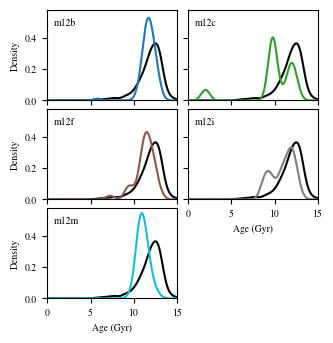

In [10]:
fig, axs = plt.subplots(3, 2, figsize=(3.5, 3.75))
plt.subplots_adjust(hspace=0.09, wspace=0.08)

# Age grid for PDFs
tgrid = np.linspace(0, 15, 1000)

# Histogram bins
bins = np.arange(0, 15.2, 0.2)

# ----------------------------------------------------------
# MW PDF (computed once)
# ----------------------------------------------------------

pdf_mw = np.zeros_like(tgrid)

for age, err in zip(mw_gcs["Mean_tau"], mw_gcs["Mean_tau_err"]):
    pdf_mw += norm.pdf(tgrid, loc=age, scale=err)

pdf_mw /= len(mw_gcs)
pdf_mw /= np.trapz(pdf_mw, tgrid)

# ----------------------------------------------------------
# MW histogram (normalized)
# ----------------------------------------------------------

mw_counts, _ = np.histogram(mw_gcs["Mean_tau"], bins=bins, density=True)

bin_centres = 0.5 * (bins[:-1] + bins[1:])

# ----------------------------------------------------------
# Simulations
# ----------------------------------------------------------

for i, ax in enumerate(axs.flatten()):
    if i == 5:
        ax.axis("off")
        continue

    sim = sim_lst[i]

    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    pdf_sim = np.zeros_like(tgrid)
    hist_sim = np.zeros(len(bins) - 1)

    n_realizations = 0

    for it_id in ghost_data.keys():
        src_dat = ghost_data[it_id]["source"]

        smsk = src_dat["tdis"][()] == -1
        tfors = timez0 - src_dat["tfor"][smsk]

        if len(tfors) == 0:
            continue

        # --------------------------
        # Histogram for realization
        # --------------------------

        h, _ = np.histogram(tfors, bins=bins, density=True)
        # h, _ = np.histogram(tfors, bins=bins, density=False)

        hist_sim += h

        # --------------------------
        # PDF for realization
        # --------------------------

        pdf_this = np.zeros_like(tgrid)

        for age in tfors:
            pdf_this += norm.pdf(tgrid, loc=age, scale=0.5)

        pdf_this /= len(tfors)
        pdf_this /= np.trapz(pdf_this, tgrid)

        pdf_sim += pdf_this

        n_realizations += 1

    hist_sim /= n_realizations
    pdf_sim /= n_realizations

    # ------------------------------------------------------
    # Histograms
    # ------------------------------------------------------

    # ax.step(bin_centres, hist_sim, where="mid", color="green", lw=1.5, alpha=0.7)

    # ax.step(bin_centres, mw_counts, where="mid", color="k", lw=1.5, alpha=0.7)

    # ------------------------------------------------------
    # PDFs
    # ------------------------------------------------------

    ax.plot(tgrid, pdf_mw, color="black", lw=1.5, label="MW PDF")
    ax.plot(tgrid, pdf_sim, color=sim_colors[sim], lw=1.5, label="Simulated PDF")

    # if i == 0:
    #     ax.legend(loc="upper left")

    # ax.set_xlim(5, 15)
    ax.set_xlim(0, 15)
    ax.set_ylim(0, 0.58)

    if i in [3, 4]:
        ax.set_xlabel("Age (Gyr)")

    if i in [0, 2, 4]:
        ax.set_ylabel(r"Density")

    if i in [0, 1, 2]:
        ax.set_xticklabels([])

    if i in [1, 3]:
        ax.set_yticklabels([])

    ax.text(0.05, 0.85, sim, ha="left", va="center", transform=ax.transAxes)

    # Wasserstein distance
    cdf_sim = np.cumsum(pdf_sim)
    cdf_sim /= cdf_sim[-1]

    cdf_mw = np.cumsum(pdf_mw)
    cdf_mw /= cdf_mw[-1]

    # wd = np.trapz(np.abs(cdf_sim - cdf_mw), tgrid)

    # print(f"{sim}: age distribution differs from MW by {wd:.2f} Gyr (Wasserstein distance)")

    median_sim = np.interp(0.5, cdf_sim, tgrid)
    median_mw = np.interp(0.5, cdf_mw, tgrid)

    delta_med = median_sim - median_mw

    print(np.round(median_mw, 2), np.round(median_sim, 2))

    if delta_med < 0:
        print(f"{sim}: median GC age is {abs(delta_med):.2f} Gyr younger than MW")
    else:
        print(f"{sim}: median GC age is {delta_med:.2f} Gyr older than MW")

    print()

save_loc = "../data/figures/gc_plots/age_distribution.pdf"
plt.savefig(save_loc, bbox_inches="tight")

In [16]:
ghost_data["it001"]["source"].keys()

<KeysViewHDF5 ['feh', 'gcid', 'grpid', 'halo.r.avg', 'halo.r.avg.pre', 'halo.r.birth', 'halo_tfor', 'host.r.avg', 'host.r.avg.pos', 'host.r.avg.pre', 'host.r.birth', 'logm_tfor', 'logm_tz0', 'pidx_snap600', 'ptype', 'pxyz_snap600', 's_flag', 'sa_flag', 'snap_tacc', 'snap_tfor', 'snap_tforp', 'tacc', 'tdis', 'tfor', 'tideig.avg', 'tideig.avg.pos', 'tideig.avg.pre', 'torb_600', 'vxyz_snap600']>

In [ ]:
ghost_data["it001"]["snapshots"]["snap600"]

<KeysViewHDF5 ['age', 'bnd_flag', 'circ', 'ecc', 'ek', 'ep', 'et', 'gcid', 'grpid', 'halo.pos.sph', 'halo.vel.sph', 'halo_tid', 'halo_tidx', 'host.pos.sph', 'host.vel.sph', 'inc', 'logm', 'nacc_flag', 'pidx', 'ptype', 's_flag', 'sa_flag', 'tideig']>

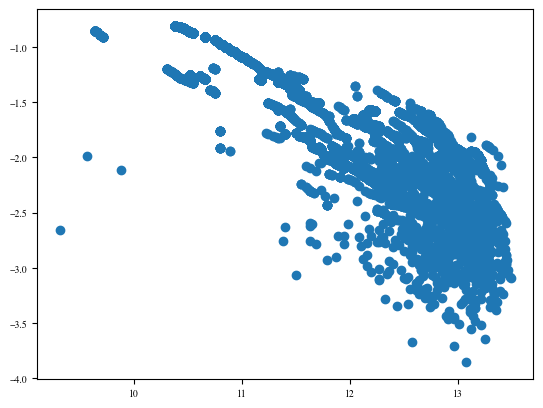

In [26]:
age = timez0 - ghost_data["it001"]["source"]["tfor"][()]
feh = ghost_data["it001"]["source"]["feh"][()]
plt.scatter(age, feh)

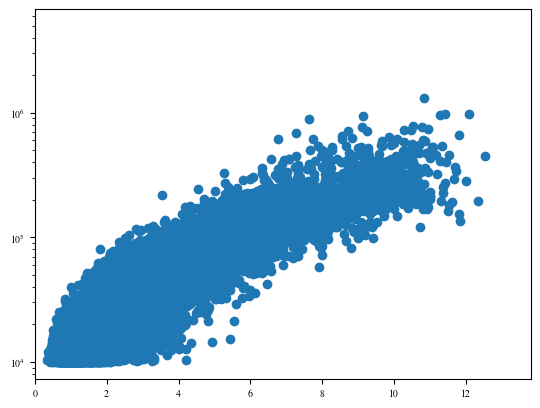

In [46]:
mfor = 10 ** ghost_data["it001"]["source"]["logm_tfor"][()]
adis = ghost_data["it001"]["source"]["tdis"][()] - ghost_data["it001"]["source"]["tfor"][()]
c = ghost_data["it001"]["source"]["torb_600"][()]

plt.scatter(adis, mfor)
plt.xlim(0, timez0)
# plt.colorbar()

# plt.xscale("log")
plt.yscale("log")

In [42]:
ghost_data["it001"]["source"].keys()

<KeysViewHDF5 ['feh', 'gcid', 'grpid', 'halo.r.avg', 'halo.r.avg.pre', 'halo.r.birth', 'halo_tfor', 'host.r.avg', 'host.r.avg.pos', 'host.r.avg.pre', 'host.r.birth', 'logm_tfor', 'logm_tz0', 'pidx_snap600', 'ptype', 'pxyz_snap600', 's_flag', 'sa_flag', 'snap_tacc', 'snap_tfor', 'snap_tforp', 'tacc', 'tdis', 'tfor', 'tideig.avg', 'tideig.avg.pos', 'tideig.avg.pre', 'torb_600', 'vxyz_snap600']>